# Detecção de fraude em cartão de crédito
**Kaggle Playground Series S6E11: Predicting Credit Card Fraud**

**Objetivo:** prever a probabilidade de `is_fraud` para cada transação do conjunto de teste.
**Métrica:** área sob a curva ROC (ROC AUC).

Etapas: carga e checagem, análise exploratória, modelo de referência, engenharia de atributos,
três modelos de gradient boosting com validação cruzada, combinação e geração de `submission.csv`.

*Opcional:* adicione em **Add Input** o dataset público "Credit Card Fraud Detection 2026" (uditjain13).
O notebook funciona com ou sem ele.

## 1. Configuração e carga dos dados

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import rankdata
warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 3
MAX_ROUNDS = 1500
EARLY_STOP = 50
TARGET = "is_fraud"
INPUT = Path("/home/rafazzz/Desktop/CESUPA/Ricardo_Rodrigo/Engenharia_de_software/Atividade_complementar_2Bimestre/dados")

def localizar_dados(raiz):
    # Procura a pasta da competição (train.csv + test.csv com a coluna alvo)
    for p in sorted(raiz.rglob("train.csv")):
        if (p.parent / "test.csv").exists() and TARGET in pd.read_csv(p, nrows=1).columns:
            return p.parent
    raise FileNotFoundError("Dados da competição não encontrados. Use Add Input > Competition.")

def localizar_original(raiz):
    for p in sorted(raiz.rglob("*.csv")):
        cols = pd.read_csv(p, nrows=1).columns
        necessarias = set(pd.read_csv(localizar_dados(raiz) / "test.csv", nrows=1).columns) - {"id"}
        if "transaction_id" in cols and TARGET in cols and necessarias <= set(cols):
            return p
    return None

pasta = localizar_dados(INPUT)
train = pd.read_csv(pasta / "train.csv")
test = pd.read_csv(pasta / "test.csv")
caminho_orig = localizar_original(INPUT)
original = pd.read_csv(caminho_orig) if caminho_orig else None
print("train:", train.shape, "| test:", test.shape,
      "| original:", None if original is None else original.shape)

train: (699960, 26) | test: (299984, 25) | original: None


## 2. Checagem de qualidade e análise exploratória

In [2]:
BOOL = ["is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch",
        "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]
CAT = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]

def padronizar(df):
    df = df.copy()
    for c in BOOL:
        df[c] = df[c].astype(str).str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0}).astype("int8")
    return df

train, test = padronizar(train), padronizar(test)
if original is not None:
    original = padronizar(original).drop(columns="transaction_id")

BASE = [c for c in test.columns if c != "id"]
faltantes = set(BASE) - set(train.columns)
assert not faltantes, f"Colunas ausentes no treino: {faltantes}"

print("Valores ausentes (treino, teste):", train.isna().sum().sum(), test.isna().sum().sum())
print("Linhas duplicadas no treino:", train[BASE].duplicated().sum())
print(f"Taxa de fraude: {train[TARGET].mean():.4%}")
train[BASE].describe().T

Valores ausentes (treino, teste): 0 0
Linhas duplicadas no treino: 0
Taxa de fraude: 1.6700%


,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


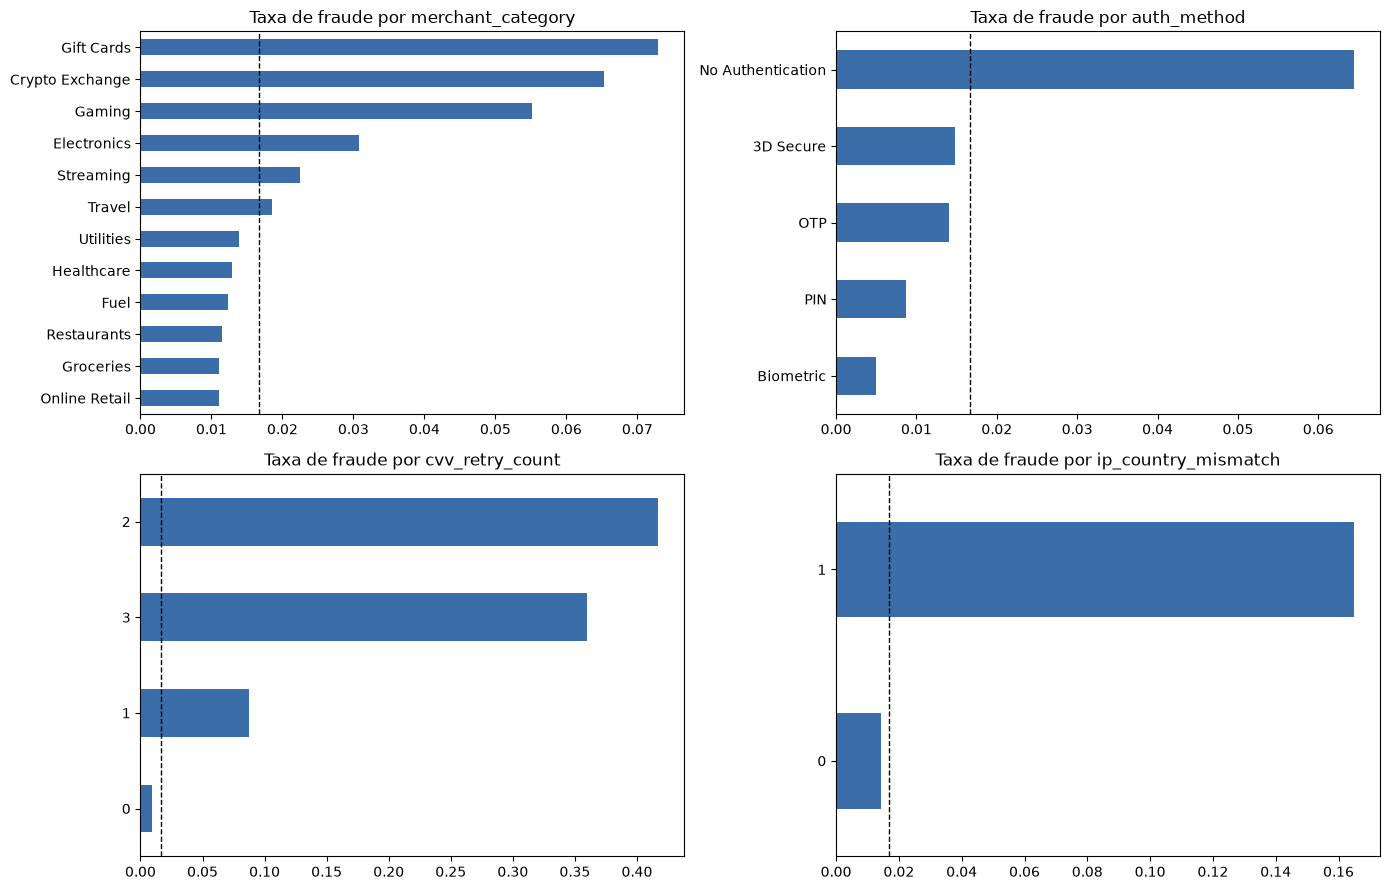

In [3]:
taxa_geral = train[TARGET].mean()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ["merchant_category", "auth_method", "cvv_retry_count", "ip_country_mismatch"]):
    train.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax, color="#3b6ea8")
    ax.axvline(taxa_geral, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Taxa de fraude por {col}")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [4]:
# Poder de separação de cada atributo numérico sozinho (AUC univariada)
numericas = [c for c in BASE if c not in CAT]
auc_uni = {c: roc_auc_score(train[TARGET], train[c]) for c in numericas}
pd.Series(auc_uni, name="AUC univariada").sort_values(ascending=False).to_frame()

,AUC univariada
merchant_risk_score,0.748936
velocity_score,0.710793
cvv_retry_count,0.708083
is_new_merchant,0.642243
customer_age,0.624724
txn_count_last_24h,0.620310
ip_country_mismatch,0.572957
is_foreign_transaction,0.557377
used_vpn,0.550236
amount_usd,0.544849


## 3. Engenharia de atributos
Cada atributo novo parte de uma hipótese sobre fraude. Nenhum usa o alvo, o que evita vazamento.

| Atributo | Hipótese |
|---|---|
| `red_flags` | vários sinais de alerta juntos pesam mais |
| `amount_to_balance` | gastar grande parte do saldo é suspeito |
| `log_amount`, `log_distance` | reduzem a assimetria |
| `risk_x_velocity` | lojista arriscado com muitas transações |
| `txn_per_gap` | rajada de transações em pouco tempo |
| `hour_sin`, `hour_cos`, `is_night` | a hora é cíclica |
| `auth_channel`, `merchant_auth` | combinações de categorias |
| `*_freq` | quão comum é cada valor |

In [5]:
def criar_atributos(df):
    X = df[BASE].copy()
    X["red_flags"] = X[BOOL].sum(axis=1) + (X["cvv_retry_count"] > 0).astype(int)
    X["amount_to_balance"] = X["amount_usd"] / (X["account_balance_usd"].abs() + 1)
    X["log_amount"] = np.log1p(X["amount_usd"].clip(lower=0))
    X["log_distance"] = np.log1p(X["distance_from_home_km"].clip(lower=0))
    X["risk_x_velocity"] = X["merchant_risk_score"] * X["velocity_score"]
    X["txn_per_gap"] = X["txn_count_last_24h"] / (X["hours_since_last_txn"] + 0.1)
    angulo = 2 * np.pi * X["time_of_day_hour"] / 24
    X["hour_sin"], X["hour_cos"] = np.sin(angulo), np.cos(angulo)
    X["is_night"] = (X["time_of_day_hour"] < 6).astype("int8")
    X["auth_channel"] = X["auth_method"].astype(str) + "|" + X["channel"].astype(str)
    X["merchant_auth"] = X["merchant_category"].astype(str) + "|" + X["auth_method"].astype(str)
    return X

partes = [train, test] + ([original] if original is not None else [])
cortes = np.cumsum([len(p) for p in partes])[:-1]
tudo = criar_atributos(pd.concat(partes, ignore_index=True))

# Codificação por frequência (usa só os atributos)
for c in ["amount_usd", "merchant_risk_score", "velocity_score", "merchant_category", "merchant_auth"]:
    tudo[f"{c}_freq"] = tudo[c].map(tudo[c].value_counts(normalize=True)).astype(float)

cat_cols = CAT + ["auth_channel", "merchant_auth"]
for c in cat_cols:
    tudo[c] = tudo[c].astype(str).astype("category")

blocos = [tudo.iloc[i].reset_index(drop=True) for i in np.split(np.arange(len(tudo)), cortes)]
X, X_test = blocos[0], blocos[1]
X_orig = blocos[2] if original is not None else None
y = train[TARGET].astype(int).to_numpy()
y_orig = original[TARGET].astype(int).to_numpy() if original is not None else None
print("Atributos:", len(BASE), "originais ->", X.shape[1], "no total")

Atributos: 24 originais -> 40 no total


## 4. Validação e modelo de referência
Validação cruzada estratificada com 5 partes, **as mesmas para todos os modelos**.
A estratificação mantém a proporção de fraudes em cada parte. Os dados originais, quando presentes,
entram **somente no treino**, nunca na validação.

In [6]:
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X, y))
resultados = []

def registrar(nome, oof, inicio):
    auc = roc_auc_score(y, oof)
    por_fold = [roc_auc_score(y[v], oof[v]) for _, v in folds]
    resultados.append({"modelo": nome, "AUC (OOF)": auc, "desvio entre folds": np.std(por_fold),
                       "PR AUC": average_precision_score(y, oof),
                       "minutos": (time.time() - inicio) / 60})
    print(f"{nome}: AUC OOF = {auc:.5f}")
    return auc

num_base = [c for c in BASE if c not in CAT]
logistica = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), num_base),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]),
    LogisticRegression(max_iter=2000))
inicio, oof_log, pred_log = time.time(), np.zeros(len(y)), np.zeros(len(X_test))
for tr, va in folds:
    logistica.fit(X.iloc[tr][BASE], y[tr])
    oof_log[va] = logistica.predict_proba(X.iloc[va][BASE])[:, 1]
    pred_log += logistica.predict_proba(X_test[BASE])[:, 1] / N_FOLDS
_ = registrar("Regressão logística (referência)", oof_log, inicio)

Regressão logística (referência): AUC OOF = 0.94172


## 5. Modelos de gradient boosting

In [7]:
def ajustar_lgbm(Xtr, ytr, Xva, yva, cats):
    m = lgb.LGBMClassifier(n_estimators=MAX_ROUNDS, learning_rate=0.03, num_leaves=7, max_depth=3,
                           min_child_samples=100, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.7, reg_lambda=5.0, random_state=SEED, metric="auc", verbose=-1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="auc",
          callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    return m

def ajustar_xgb(Xtr, ytr, Xva, yva, cats):
    m = xgb.XGBClassifier(n_estimators=MAX_ROUNDS, learning_rate=0.03, max_depth=3,
                          min_child_weight=5, subsample=0.8, colsample_bytree=0.7, reg_lambda=5.0,
                          tree_method="hist", enable_categorical=True, eval_metric="auc",
                          early_stopping_rounds=EARLY_STOP, random_state=SEED)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m

def ajustar_cat(Xtr, ytr, Xva, yva, cats):
    m = CatBoostClassifier(iterations=MAX_ROUNDS, learning_rate=0.1, depth=4, l2_leaf_reg=5.0,
                           eval_metric="AUC", od_type="Iter", od_wait=EARLY_STOP,
                           max_ctr_complexity=1, thread_count=-1,
                           random_seed=SEED, verbose=0, allow_writing_files=False)
    m.fit(Xtr, ytr, eval_set=(Xva, yva), cat_features=cats, use_best_model=True)
    return m

def validar(nome, ajustar, colunas):
    inicio = time.time()
    oof, pred = np.zeros(len(y)), np.zeros(len(X_test))
    cats = [c for c in cat_cols if c in colunas]
    for tr, va in folds:
        Xtr, ytr = X.iloc[tr][colunas], y[tr]
        if X_orig is not None:
            Xtr = pd.concat([Xtr, X_orig[colunas]], ignore_index=True)
            ytr = np.concatenate([ytr, y_orig])
        m = ajustar(Xtr, ytr, X.iloc[va][colunas], y[va], cats)
        oof[va] = m.predict_proba(X.iloc[va][colunas])[:, 1]
        pred += m.predict_proba(X_test[colunas])[:, 1] / N_FOLDS
    auc = registrar(nome, oof, inicio)
    return oof, pred, auc, m

### 5.1 Os atributos novos ajudam?
Comparação controlada: mesmo modelo e mesmos folds, mudando só o conjunto de colunas.
Segue adiante o conjunto com maior AUC.

In [8]:
COLUNAS = list(X.columns)
lgbm = validar("LightGBM", ajustar_lgbm, COLUNAS)

LightGBM: AUC OOF = 0.94571


In [9]:
xgbm = validar("XGBoost", ajustar_xgb, COLUNAS)
catb = validar("CatBoost", ajustar_cat, COLUNAS)

XGBoost: AUC OOF = 0.94538
CatBoost: AUC OOF = 0.94547


## 6. Combinação dos modelos (blend)
Entram os três modelos de boosting e a regressão logística, que erra de forma diferente.
Como a AUC depende só da ordenação, as previsões são convertidas em postos (ranks) antes da média.
Os pesos são escolhidos nas previsões fora da amostra (OOF).

In [10]:
nomes = ["Regressão logística", "LightGBM", "XGBoost", "CatBoost"]
previsoes = [(oof_log, pred_log), lgbm[:2], xgbm[:2], catb[:2]]
postos = lambda v: rankdata(v) / len(v)
R_oof = np.column_stack([postos(p[0]) for p in previsoes])
R_test = np.column_stack([postos(p[1]) for p in previsoes])

# Seleção gulosa (hill climbing): a cada passo entra o modelo que mais melhora a média.
# Um mesmo modelo pode entrar várias vezes, o que define seu peso.
contagem = np.zeros(len(nomes))
melhor_auc, pesos = 0.0, None
for passo in range(25):
    candidatos = [(contagem + np.eye(len(nomes))[i]) / (passo + 1) for i in range(len(nomes))]
    aucs = [roc_auc_score(y, R_oof @ w) for w in candidatos]
    i = int(np.argmax(aucs))
    contagem[i] += 1
    if aucs[i] > melhor_auc:
        melhor_auc, pesos = aucs[i], candidatos[i]
oof_blend, pred_blend = R_oof @ pesos, R_test @ pesos
print("Pesos:", {n: round(float(w), 2) for n, w in zip(nomes, pesos)})
_ = registrar("Blend por ranks", oof_blend, time.time())

tabela = pd.DataFrame(resultados).sort_values("AUC (OOF)", ascending=False)
tabela.to_csv("resultados.csv", index=False)
tabela.round(5)

Pesos: {'Regressão logística': 0.0, 'LightGBM': 0.56, 'XGBoost': 0.0, 'CatBoost': 0.44}
Blend por ranks: AUC OOF = 0.94616


,modelo,AUC (OOF),desvio entre folds,PR AUC,minutos
4,Blend por ranks,0.94616,0.00224,0.50849,0.00882
1,LightGBM,0.94571,0.00231,0.50469,1.79015
3,CatBoost,0.94547,0.00217,0.50566,5.68705
2,XGBoost,0.94538,0.00226,0.50249,3.30612
0,Regressão logística (referência),0.94172,0.00271,0.48898,0.22386


## 7. Interpretação

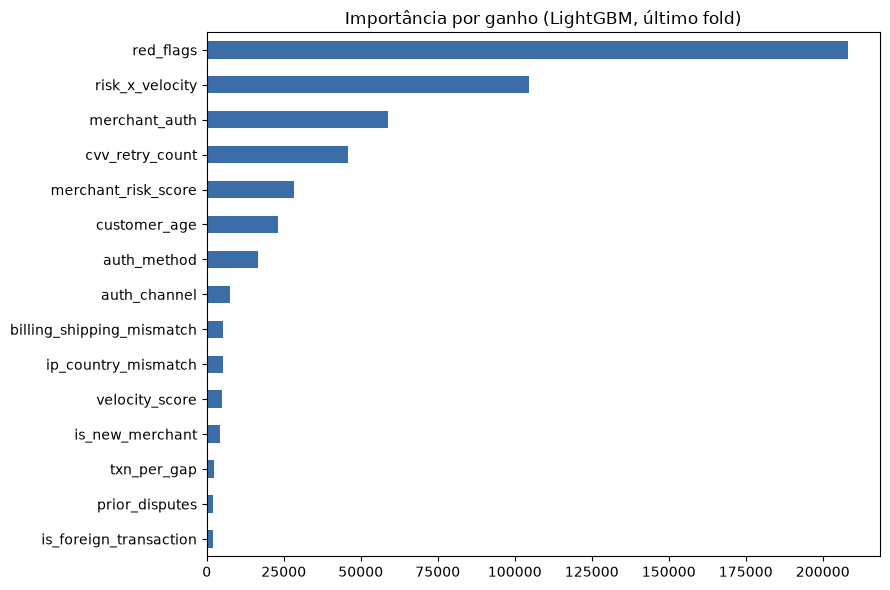

In [11]:
modelo_lgbm = lgbm[3]
imp = pd.Series(modelo_lgbm.booster_.feature_importance("gain"),
                index=modelo_lgbm.booster_.feature_name()).sort_values().tail(15)
imp.plot.barh(figsize=(9, 6), color="#3b6ea8", title="Importância por ganho (LightGBM, último fold)")
plt.tight_layout()
plt.show()

In [12]:
# Leitura de negócio: se só as transações de maior risco forem revisadas, quantas fraudes são pegas?
ordem = np.argsort(-oof_blend)
linhas = []
for frac in [0.005, 0.01, 0.02, 0.05]:
    k = int(len(y) * frac)
    achadas = y[ordem[:k]].sum()
    linhas.append({"revisadas": f"{frac:.1%}", "fraudes capturadas": f"{achadas / y.sum():.1%}",
                   "precisão": f"{achadas / k:.1%}"})
pd.DataFrame(linhas)

,revisadas,fraudes capturadas,precisão
0,0.5%,24.7%,82.7%
1,1.0%,38.8%,64.7%
2,2.0%,53.7%,44.9%
3,5.0%,70.9%,23.7%


## 8. Arquivo de submissão

In [13]:
sub = pd.DataFrame({"id": test["id"], TARGET: pred_blend})
assert len(sub) == len(test) and sub["id"].is_unique
assert sub[TARGET].between(0, 1).all()
sub.to_csv("submission.csv", index=False)
sub.head()

,id,is_fraud
0,699960,0.115808
1,699961,0.106744
2,699962,0.956976
3,699963,0.445469
4,699964,0.455866


## 9. Limitações e próximos passos
* A parada antecipada e a escolha dos pesos usam os dados de validação, então a AUC OOF é um pouco otimista.
* Os dados são sintéticos: os resultados não valem automaticamente para um banco real.
* Próximos passos: codificação do alvo dentro de cada fold, várias sementes e busca de hiperparâmetros.